In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import json

EPILL = Path("../data/raw/epillid/ePillID_data")
MEDI_ROOT = Path("../data/raw/MEDISEG")

In [2]:
df = pd.read_csv(EPILL / "all_labels.csv")
print(df.shape)                       # expect (13532, 9)
print(df.is_ref.value_counts())       # expect 9804 reference, 3728 consumer
print("pill types:", df.pilltype_id.nunique())   # expect 4902
cons = df[~df.is_ref]
print("types with consumer images:", cons.pilltype_id.nunique())  # expect 960

(13532, 9)
is_ref
True     9804
False    3728
Name: count, dtype: int64
pill types: 4902
types with consumer images: 960


count    960.000000
mean       3.883333
std        1.253539
min        1.000000
25%        3.000000
50%        4.000000
75%        5.000000
max        5.000000
Name: count, dtype: float64


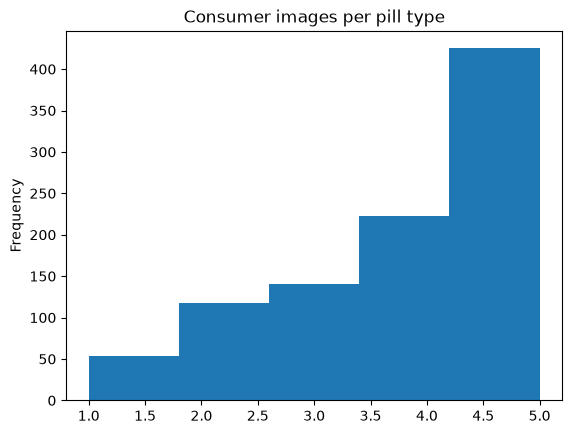

In [3]:
per_type = cons.pilltype_id.value_counts()
per_type.plot(kind = "hist" , bins = 5,title="Consumer images per pill type" )
print(per_type.describe())

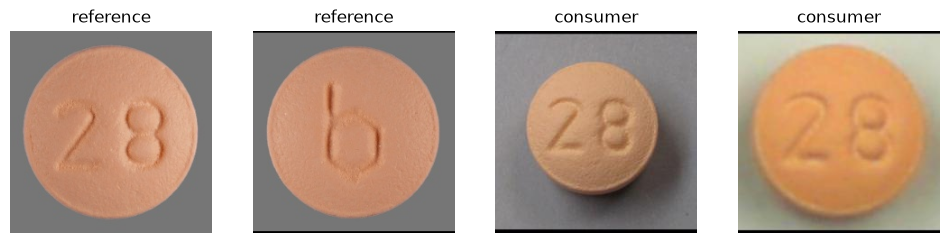

In [4]:
ptype = per_type.index[0]
rows = df[df.pilltype_id == ptype]
sample = pd.concat([rows[rows.is_ref].head(2), rows[~rows.is_ref].head(2)])
fig, axes = plt.subplots(1, len(sample), figsize=(3*len(sample), 3))
for ax, (_, r) in zip(axes, sample.iterrows()):
        
        ax.imshow(Image.open(EPILL / "classification_data" / r.image_path))
        ax.set_title("reference" if r.is_ref else "consumer")
        ax.axis("off")

In [5]:
for p in MEDI_ROOT.rglob("annotations.json"):
    print(p)

ANN = next(MEDI_ROOT.rglob("32pills/annotations.json"))

coco = json.load(open(ANN))
print(coco.keys())
print("images:", len(coco["images"]))
print("boxes:", len(coco["annotations"]))
print("classes:", len(coco["categories"]))
print(coco["images"][0])
print(coco["annotations"][0])

..\data\raw\MEDISEG\32pills\annotations.json
..\data\raw\MEDISEG\3pills\annotations.json
dict_keys(['info', 'licenses', 'categories', 'images', 'annotations'])
images: 8261
boxes: 14069
classes: 33
{'id': 0, 'license': 1, 'file_name': 'IMG_4594_jpg.rf.002922367d848d76521c39c022a77df7.jpg', 'height': 640, 'width': 640, 'date_captured': '2024-08-20T22:23:25+00:00'}
{'id': 0, 'image_id': 0, 'category_id': 10, 'bbox': [317, 325, 27.048, 26.746], 'area': 723.416, 'segmentation': [[320.778, 328.794, 318.095, 332.016, 317.381, 333.635, 316.905, 335.317, 316.714, 339.492, 317.079, 342.016, 317.683, 343.984, 320.667, 348.238, 322.587, 349.73, 324.492, 350.81, 328.619, 351.825, 331.365, 351.825, 335.683, 350.81, 339.381, 348.476, 341.54, 345.905, 342.381, 344.349, 343.095, 342.429, 343.762, 338.429, 343.46, 335.857, 342.857, 334, 341.063, 330.825, 339.984, 329.635, 337, 326.937, 335.254, 326.048, 333.111, 325.27, 330.349, 325.079, 328.016, 325.381, 324.619, 326.397, 324.492, 326.524, 322.048, 32

count    8259.000000
mean        1.703475
std         1.570990
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        11.000000
dtype: float64


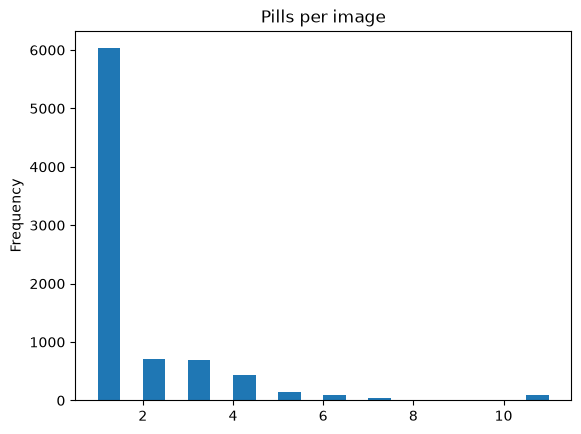

In [6]:
ann = pd.DataFrame(coco["annotations"])
boxes_per_img = ann.groupby("image_id").size()
print(boxes_per_img.describe())
boxes_per_img.plot(kind="hist", bins=20, title="Pills per image")
plt.show()

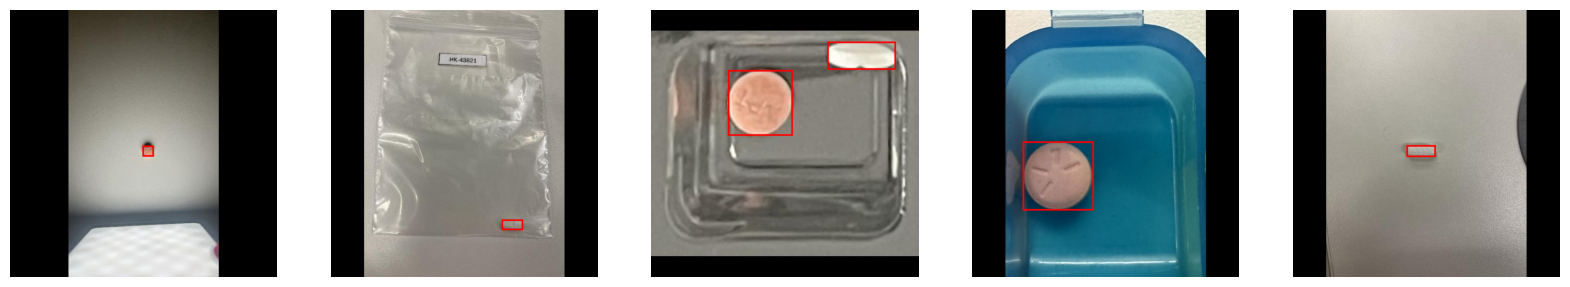

In [7]:
from PIL import ImageDraw
img_dir = ANN.parent / "images"
imgs = {i["id"]: i for i in coco["images"]}
fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, img_id in zip(axes, list(boxes_per_img.index[:5])):
        
    im = Image.open(img_dir / imgs[img_id]["file_name"]).convert("RGB")
    d = ImageDraw.Draw(im)
    for _, a in ann[ann.image_id == img_id].iterrows():
            x, y, w, h = a.bbox
            d.rectangle([x, y, x + w, y + h], outline="red", width=4)
            ax.imshow(im); ax.axis("off")
plt.show()
